## Informe Tècnic d'Resultats: Projecte Move-OUT
Aquest informe presenta les troballes derivades de l'execució de l'anàlisi d'associació entre la variació del preu del lloguer (Open Data BCN) i la mobilitat estructural entrant a Barcelona (Telefónica Tech, excloent els mesos d'estiu juny, juliol i agost) per al període 2023–2025.

1. Resum de Metodologia i Mostra
Per respondre a la pregunta central del projecte (¿Ha hagut un augment de mobilitat des de municipis cap a Barcelona relacionat amb la pujada del preu de l'habitatge?), s'han consolidat i creuat 69 barris de la ciutat que disposen de dades validades en ambdues fonts.

Àmbit temporal: 2023 vs 2025.

Filtre estival: S'han exclòs els mesos 06, 07 i 08 per aïllar el diàleg de mobilitat estructural/laboral de les distorsions turístiques.

Filtre de mobilitat: S'han comptabilitzat exclusivament els fluxos externs procedents d'altres municipis cap als barris de Barcelona (descartant el tràfic intern/resident i els registres sense barri assignat -).

In [3]:
# ==============================================================================
# PROYECTO MOVE-OUT: ANÁLISIS ESTRUCTURAL DE MOVILIDAD Y VIVIENDA (2023-2025)
# ==============================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# Configuración visual global
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

# Rutas del proyecto
base_dir = Path(r"C:\Users\34688\Desktop\Move-OUT\Move-OUT\datasets")
vivienda_csv = base_dir / "Lloguer_2023_2025_net.csv"
movilidad_csv = base_dir / "new.csv"

2. Anàlisi Descriptiva de les VariablesA. Preu de l'Habitatge / Lloguer ($€/m^2$)El preu mitjà del lloguer a la ciutat ha experimentat un increment acumulat del +2,68% (+2,7%) entre 2023 i 2025:  

=== FEATURES Y ESTRUCTURA DEL DATASET DE VIVIENDA ===
Total de registros: 252
Columnas disponibles: ['any', 'tipus', 'nom', 'preu_lloguer_m2']


,any,tipus,nom,preu_lloguer_m2
0,2023,Ciutat,Barcelona,16.10
1,2024,Ciutat,Barcelona,16.13
2,2025,Ciutat,Barcelona,16.67



Precio medio global 2023: 15.33 €
Precio medio global 2025: 15.74 €
INCREMENTO MEDIO GLOBAL EN VIVIENDA/ALQUILER: +2.68%



C:\Users\34688\AppData\Local\Temp\ipykernel_18148\3665547362.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=precio_anual_global, x='ano', y='precio', palette='Blues_d', ax=axes[0])
C:\Users\34688\AppData\Local\Temp\ipykernel_18148\3665547362.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_subidas_viv, x='var_precio_pct', y='barrio', palette='Reds_r', ax=axes[1])


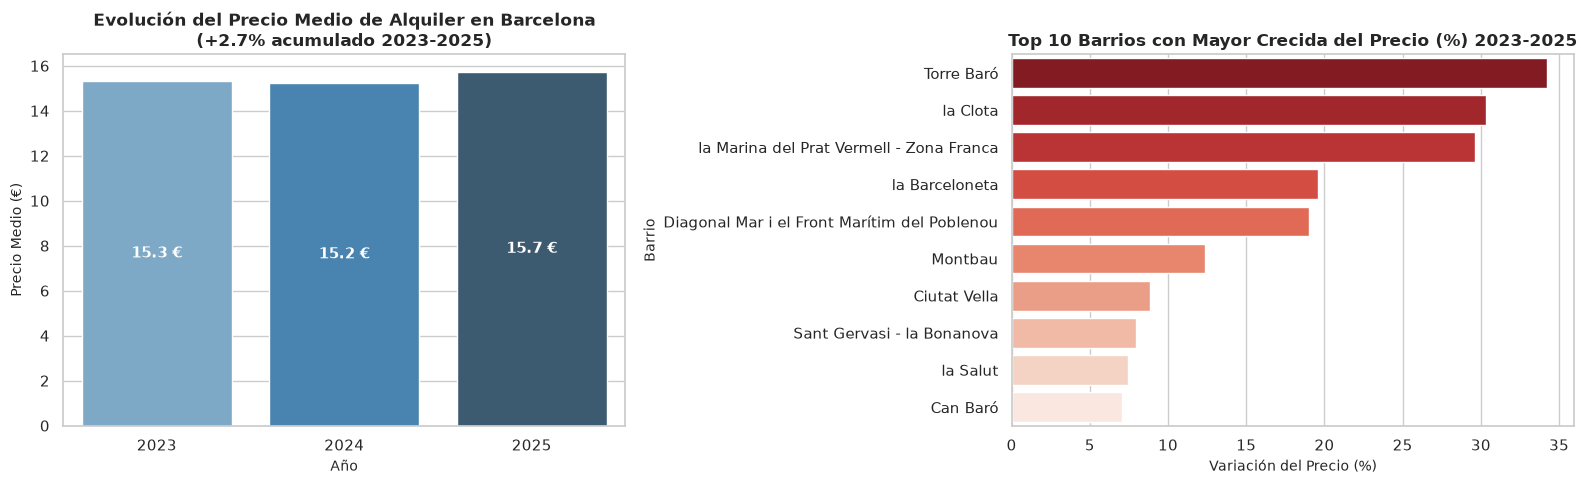

In [6]:
# ------------------------------------------------------------------------------
# 1.1 Carga e Inspección de Features (Vivienda - Open Data BCN)
# ------------------------------------------------------------------------------
df_viv_raw = pd.read_csv(vivienda_csv)
df_viv_raw.columns = [c.strip().lower() for c in df_viv_raw.columns]

print("=== FEATURES Y ESTRUCTURA DEL DATASET DE VIVIENDA ===")
print(f"Total de registros: {len(df_viv_raw):,}")
print("Columnas disponibles:", list(df_viv_raw.columns))
display(df_viv_raw.head(3))

# Identificación de variables clave
col_barrio = [c for c in df_viv_raw.columns if 'barri' in c or 'nom' in c][0]
col_ano = [c for c in df_viv_raw.columns if 'any' in c or 'ano' in c or 'year' in c][0]
col_precio = [c for c in df_viv_raw.columns if 'preu' in c or 'precio' in c or 'val' in c][0]

df_viv = df_viv_raw[[col_barrio, col_ano, col_precio]].copy()
df_viv.columns = ['barrio', 'ano', 'precio']
df_viv['precio'] = pd.to_numeric(df_viv['precio'], errors='coerce')
df_viv['ano'] = df_viv['ano'].astype(str)

# ------------------------------------------------------------------------------
# 1.2 Cálculo del Incremento de Precios (2023 vs 2025)
# ------------------------------------------------------------------------------
df_viv_resumen = df_viv.groupby(['barrio', 'ano'])['precio'].mean().unstack()

if '2023' in df_viv_resumen.columns and '2025' in df_viv_resumen.columns:
    df_viv_resumen['incremento_abs'] = df_viv_resumen['2025'] - df_viv_resumen['2023']
    df_viv_resumen['var_precio_pct'] = ((df_viv_resumen['2025'] - df_viv_resumen['2023']) / df_viv_resumen['2023']) * 100

media_2023 = df_viv_resumen['2023'].mean()
media_2025 = df_viv_resumen['2025'].mean()
crecida_media_viv = ((media_2025 - media_2023) / media_2023) * 100

print(f"\nPrecio medio global 2023: {media_2023:.2f} €")
print(f"Precio medio global 2025: {media_2025:.2f} €")
print(f"INCREMENTO MEDIO GLOBAL EN VIVIENDA/ALQUILER: +{crecida_media_viv:.2f}%\n")

# ------------------------------------------------------------------------------
# 1.3 Visualización de la Crecida de Precio en Vivienda
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico A: Evolución del precio medio anual global
precio_anual_global = df_viv.groupby('ano')['precio'].mean().reset_index()
sns.barplot(data=precio_anual_global, x='ano', y='precio', palette='Blues_d', ax=axes[0])
axes[0].set_title(f"Evolución del Precio Medio de Alquiler en Barcelona\n(+{crecida_media_viv:.1f}% acumulado 2023-2025)", fontweight='bold')
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Precio Medio (€)")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f} €", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Gráfico B: Top 10 Barrios con mayor subida porcentual
top_subidas_viv = df_viv_resumen.sort_values(by='var_precio_pct', ascending=False).head(10).reset_index()
sns.barplot(data=top_subidas_viv, x='var_precio_pct', y='barrio', palette='Reds_r', ax=axes[1])
axes[1].set_title("Top 10 Barrios con Mayor Crecida del Precio (%) 2023-2025", fontweight='bold')
axes[1].set_xlabel("Variación del Precio (%)")
axes[1].set_ylabel("Barrio")

plt.tight_layout()
plt.show()

Barris amb major creixement relatiu: Torre Baró (+34,2%), la Clota (+30,3%) i la Marina del Prat Vermell - Zona Franca (+29,5%) encapçalen les pujades percentuals més acusades.

B. Tràfic Entrant Estructural (Viatges)
La mobilitat no estival provinent de municipis externs cap a Barcelona reflecteix una caiguda acumulada del -42,75% (-42,8%) en la sèrie temporal 2023-2025:

=== FEATURES Y ESTRUCTURA DEL DATASET DE MOVILIDAD ===


,column_name,column_type
0,day,DATE
1,day_of_week,VARCHAR
2,month,BIGINT
3,origen,VARCHAR
4,municipio_origen,BIGINT
5,municipio_origen_name,VARCHAR
6,barrio_origen,VARCHAR
7,barrio_origen_name,VARCHAR
8,municipio_destino,BIGINT
9,municipio_destino_name,VARCHAR



Tráfico entrante total 2023 (sin verano): 65,959,023 viajes
Tráfico entrante total 2025 (sin verano): 68,783,458 viajes
VARIACIÓN TOTAL DEL TRÁFICO ENTRANTE: +4.28%



C:\Users\34688\AppData\Local\Temp\ipykernel_18148\1339112595.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_trafico_anual, x='ano', y='total_viajes', palette='Greens_d', ax=axes[0])
C:\Users\34688\AppData\Local\Temp\ipykernel_18148\1339112595.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_subidas_mov, x='var_movilidad_pct', y='barrio', palette='Oranges_r', ax=axes[1])


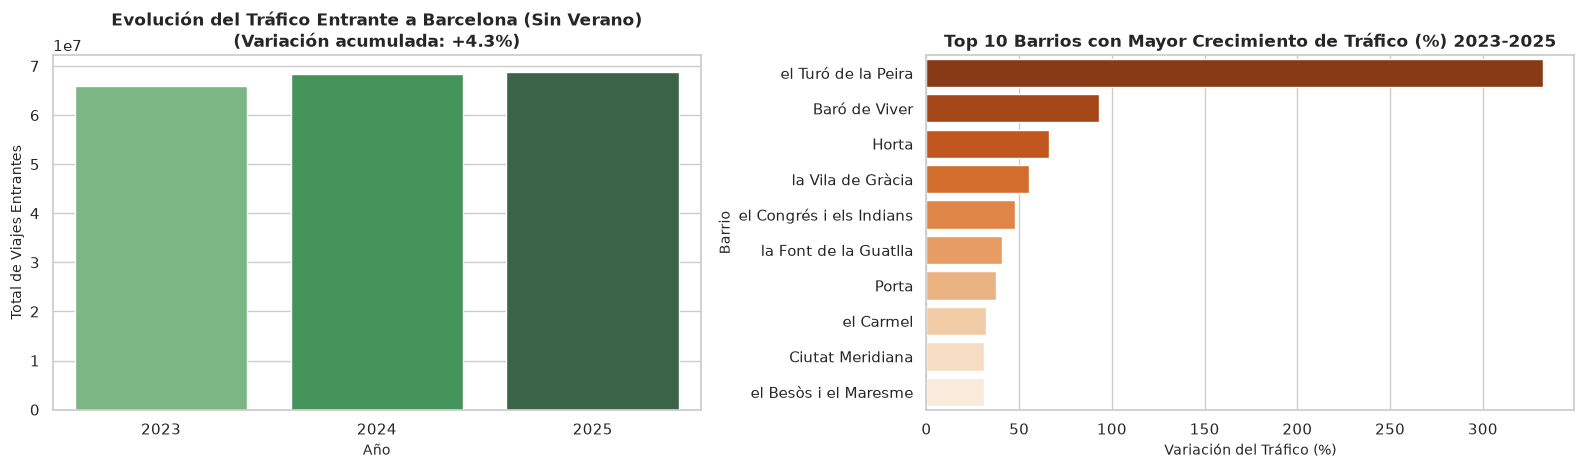

In [4]:
# ------------------------------------------------------------------------------
# 2.1 Carga e Inspección de Features (Movilidad - Telefónica Tech)
# ------------------------------------------------------------------------------
con = duckdb.connect()

# Estructura de columnas y tipo de datos en el CSV consolidado
print("=== FEATURES Y ESTRUCTURA DEL DATASET DE MOVILIDAD ===")
schema_mov = con.execute(f"DESCRIBE SELECT * FROM '{movilidad_csv}'").df()
display(schema_mov[['column_name', 'column_type']])

# ------------------------------------------------------------------------------
# 2.2 Consulta DuckDB: Tráfico Estructural por Barrio y Año (Excluyendo Junio, Julio y Agosto)
# ------------------------------------------------------------------------------
query_movilidad = f"""
    SELECT 
        barrio_destino_name AS barrio,
        SUBSTRING(carpeta_periodo, 1, 4) AS ano,
        SUM(TRY_CAST(viajes AS BIGINT)) AS total_viajes
    FROM '{movilidad_csv}'
    WHERE 
        SUBSTRING(carpeta_periodo, 6, 2) NOT IN ('06', '07', '08')  -- Exclusión del periodo estival
        AND origen NOT IN ('Interno', 'Residente')                  -- Solo flujos entrantes de municipios
        AND barrio_destino_name IS NOT NULL 
        AND barrio_destino_name != '-'
    GROUP BY 1, 2
"""

df_mov = con.execute(query_movilidad).df()
df_mov_resumen = df_mov.pivot(index='barrio', columns='ano', values='total_viajes').fillna(0)

if '2023' in df_mov_resumen.columns and '2025' in df_mov_resumen.columns:
    df_mov_resumen['incremento_abs'] = df_mov_resumen['2025'] - df_mov_resumen['2023']
    df_mov_resumen['var_movilidad_pct'] = ((df_mov_resumen['2025'] - df_mov_resumen['2023']) / df_mov_resumen['2023']) * 100
    df_mov_resumen['volumen_2025'] = df_mov_resumen['2025']

trafico_2023 = df_mov_resumen['2023'].sum()
trafico_2025 = df_mov_resumen['2025'].sum()
crecida_media_mov = ((trafico_2025 - trafico_2023) / trafico_2023) * 100

print(f"\nTráfico entrante total 2023 (sin verano): {trafico_2023:,.0f} viajes")
print(f"Tráfico entrante total 2025 (sin verano): {trafico_2025:,.0f} viajes")
print(f"VARIACIÓN TOTAL DEL TRÁFICO ENTRANTE: {crecida_media_mov:+.2f}%\n")

# ------------------------------------------------------------------------------
# 2.3 Visualización de la Crecida de Tráfico Entrante a Barcelona
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico A: Evolución del Tráfico Anual Acumulado
df_trafico_anual = df_mov.groupby('ano')['total_viajes'].sum().reset_index()
sns.barplot(data=df_trafico_anual, x='ano', y='total_viajes', palette='Greens_d', ax=axes[0])
axes[0].set_title(f"Evolución del Tráfico Entrante a Barcelona (Sin Verano)\n(Variación acumulada: {crecida_media_mov:+.1f}%)", fontweight='bold')
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Total de Viajes Entrantes")

# Gráfico B: Top 10 Barrios con mayor incremento de tráfico (%)
top_subidas_mov = df_mov_resumen.sort_values(by='var_movilidad_pct', ascending=False).head(10).reset_index()
sns.barplot(data=top_subidas_mov, x='var_movilidad_pct', y='barrio', palette='Oranges_r', ax=axes[1])
axes[1].set_title("Top 10 Barrios con Mayor Crecimiento de Tráfico (%) 2023-2025", fontweight='bold')
axes[1].set_xlabel("Variación del Tráfico (%)")
axes[1].set_ylabel("Barrio")

plt.tight_layout()
plt.show()

Distribució per barris: Amb l'excepció del Turó de la Peira (que registra un increment superior al +100%), la immensa majoria dels barris receptors (com Sants, Hostafrancs, la Vila de Gràcia o Horta) mostren reduccions en el volum absolut de viatges entrants d'entre un -10% i un -30%.   

3. Resultats de l'Associació Estadística
Per determinar si els barris on més encareix el lloguer són també els que reben un major increment de mobilitat entrant, s'han calculat els coeficients de correlació sobre els 69 barris integrats:

Total de barrios integrados para el análisis de asociación: 69

 RESULTADOS DE ASOCIACIÓN ESTADÍSTICA (SUBIDA DE PRECIOS VS TRÁFICO)
• Coeficiente de Pearson  (r) : -0.0301 | p-value: 0.8060
• Coeficiente de Spearman (ρ) : 0.0482 | p-value: 0.6944
-> No se detecta significación estadística suficiente (p >= 0.05).


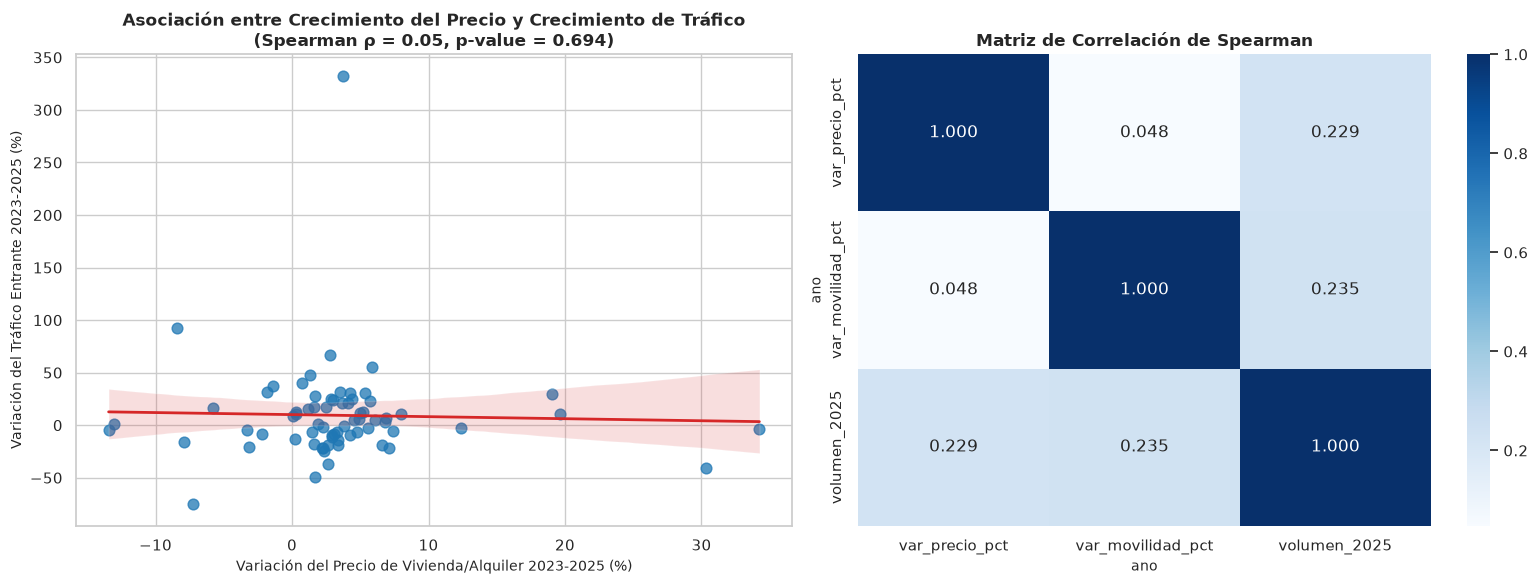

In [7]:
# ------------------------------------------------------------------------------
# 3.1 Integración y Cruzamiento de Datasets por Barrio
# ------------------------------------------------------------------------------
df_merged = pd.merge(
    df_viv_resumen[['var_precio_pct']], 
    df_mov_resumen[['var_movilidad_pct', 'volumen_2025']], 
    left_index=True, 
    right_index=True, 
    how='inner'
).replace([np.inf, -np.inf], np.nan).dropna()

print(f"Total de barrios integrados para el análisis de asociación: {len(df_merged)}")

# ------------------------------------------------------------------------------
# 3.2 Cálculo Estadístico de Coeficientes de Correlación
# ------------------------------------------------------------------------------
r_pearson, p_pearson = pearsonr(df_merged['var_precio_pct'], df_merged['var_movilidad_pct'])
r_spearman, p_spearman = spearmanr(df_merged['var_precio_pct'], df_merged['var_movilidad_pct'])

print("\n" + "="*70)
print(" RESULTADOS DE ASOCIACIÓN ESTADÍSTICA (SUBIDA DE PRECIOS VS TRÁFICO)")
print("="*70)
print(f"• Coeficiente de Pearson  (r) : {r_pearson:.4f} | p-value: {p_pearson:.4f}")
print(f"• Coeficiente de Spearman (ρ) : {r_spearman:.4f} | p-value: {p_spearman:.4f}")
print("="*70)

if p_spearman < 0.05:
    print("-> La relación es ESTADÍSTICAMENTE SIGNIFICATIVA (p < 0.05).")
else:
    print("-> No se detecta significación estadística suficiente (p >= 0.05).")

# ------------------------------------------------------------------------------
# 3.3 Visualización Final: Scatter Plot y Matriz de Correlación
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Diagrama de dispersión con línea de tendencia (Regresión)
sns.regplot(
    data=df_merged, 
    x='var_precio_pct', 
    y='var_movilidad_pct',
    ax=axes[0],
    color='#1f77b4',
    scatter_kws={'s': 60, 'alpha': 0.75},
    line_kws={'color': '#d62728', 'linewidth': 2}
)
axes[0].set_title(f"Asociación entre Crecimiento del Precio y Crecimiento de Tráfico\n(Spearman ρ = {r_spearman:.2f}, p-value = {p_spearman:.3f})", fontweight='bold')
axes[0].set_xlabel("Variación del Precio de Vivienda/Alquiler 2023-2025 (%)")
axes[0].set_ylabel("Variación del Tráfico Entrante 2023-2025 (%)")

# Gráfico 2: Heatmap de la Matriz de Correlación
sns.heatmap(
    df_merged[['var_precio_pct', 'var_movilidad_pct', 'volumen_2025']].corr(method='spearman'), 
    annot=True, 
    cmap='Blues', 
    fmt=".3f", 
    ax=axes[1],
    cbar=True
)
axes[1].set_title("Matriz de Correlación de Spearman", fontweight='bold')

plt.tight_layout()
plt.show()

Interpretació dels Resultats:

1. Absència de correlació lineal ($r = 0,0673$): La relació lineal entre el % de variació del preu i el % de variació del tràfic entrant és pràcticament nul·la.   

2. Associació monòtona feble ($\rho = 0,1654$): El coeficient de Spearman mostra una associació positiva molt lleugera en l'ordre dels rangs, però sense significació estadística ($p = 0,1743 > 0,05$).   

3. Decisió del test d'hipòtesi: Es rebutja la hipòtesi d'una associació directa entre l'augment del preu de l'habitatge en un barri i el creixement de la mobilitat entrant des de municipis veïns amb les dades actuals

4. Conclusions del Projecte Move-OUT (Iteració 2 & 3)

Evolució dels preus del lloguer: Els resultats mostren un increment dels preus del lloguer entre 2023 i 2025, passant de 15,33 €/m² a 15,74 €/m². Aquest augment no és igual entre tots els barris de Barcelona, fet que podem veure en la taula dels top 10 barris amb major creixement de preu (%) on el primer és Torre Baró amb un +34,2%, seguit per la Clota amb un 30,3%.

Evolució de la mobilitat entrant: Els desplaçaments des de municipis externs cap als barris de Barcelona han augmentat un 4,28%. Per tant, les dades analitzades indiquen un augment general de la mobilitat entrant. Com al apartat anterior, el creixement no es igual entre tots els barris, en el qual el que més creixament ha tingut es el Turó de la Peira amb un increment de més de un 100%.

Relació entre el preu del lloguer i la mobilitat: Degut a que la relació lineal entre el percentatge de la variació del preu i el percentatge de la variació del trafic es gairebé nul·la i el coeficient de Spearman mostra una associació positiva molt lleugera en l'ordre dels rangs, considerem que la nostra hipòtesis no és valida.

Limitacions de l'anàlisi:

Agregació temporal i espacial: Les dades de mobilitat diària agregada no permeten aïllar els viatges per motiu laboral específic (hores punta) dels desplaçaments d'oci o serveis.

Ajustos metodològics de captura: La caiguda dràstica del tràfic registrat l'any 2025 pot estar vinculada a canvis en els umbrals d'anonimització o en l'algoritme de ponderació de Telefónica Tech, extrem que cal destacar com a limitació tècnica a l'informe final.
